<a href="https://colab.research.google.com/github/akshat280706/IP-LABS/blob/main/241080009_akshat_IPLAB7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Akshat Chauhan
#241080009
#IT

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from collections import deque

Saving image to image (1)
Image dimensions: (400, 600, 3)


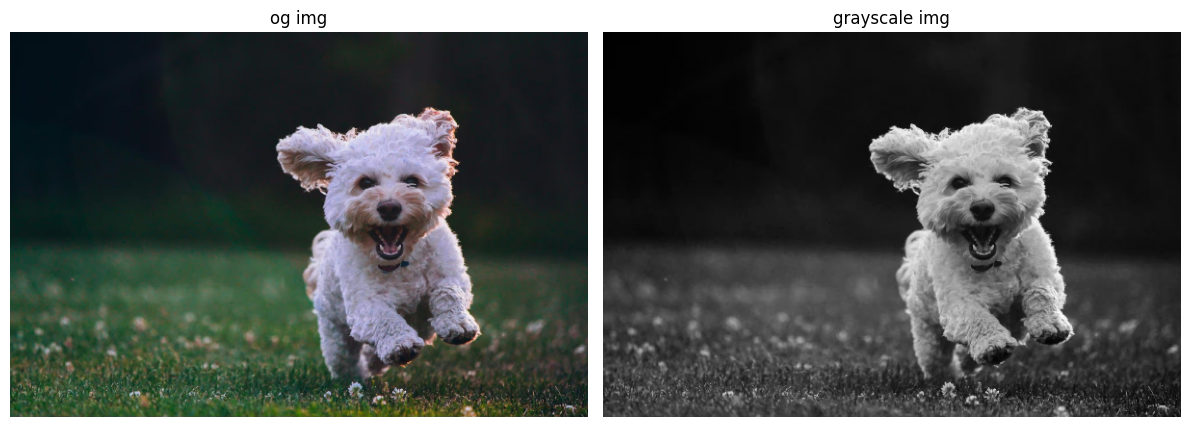

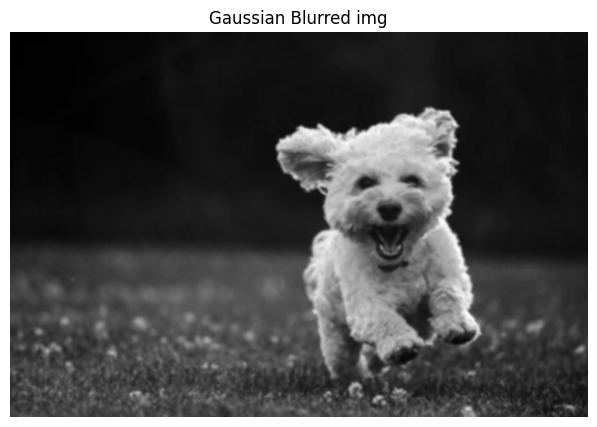

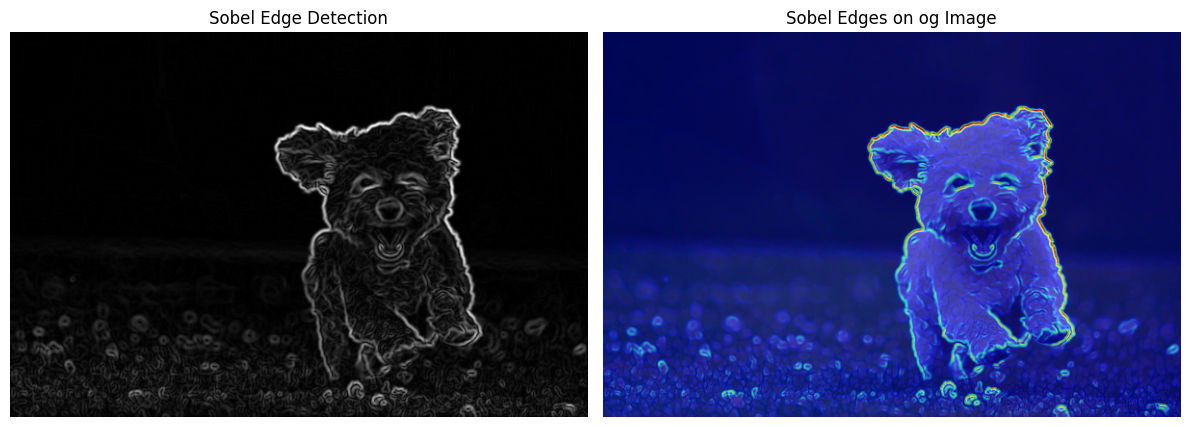

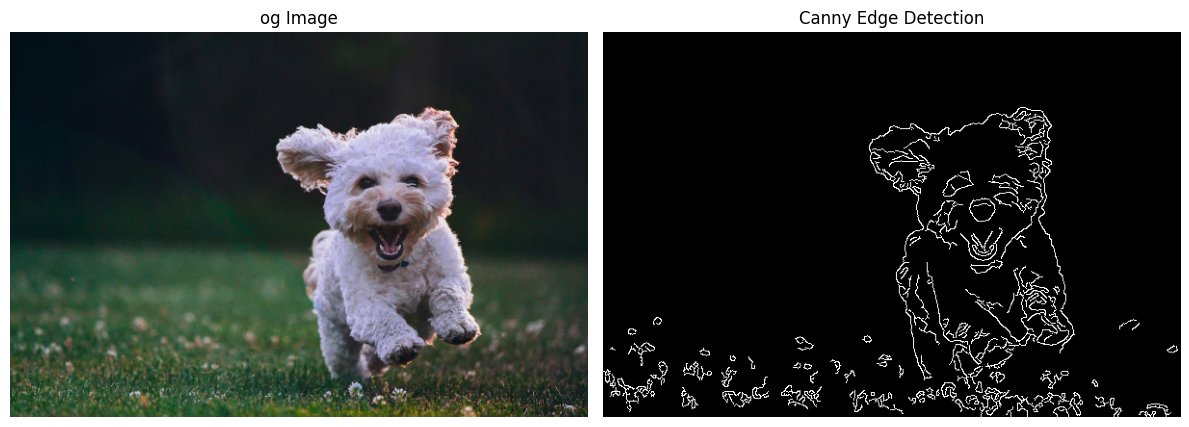

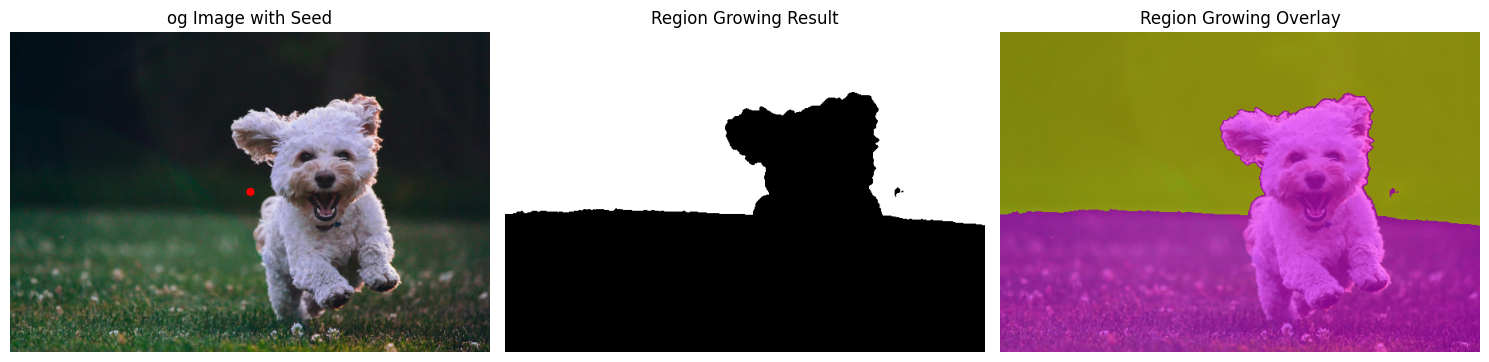

Region Growing Completed
Seed coordinates (x, y): (300, 200)
Number of segmented pixels: 115003


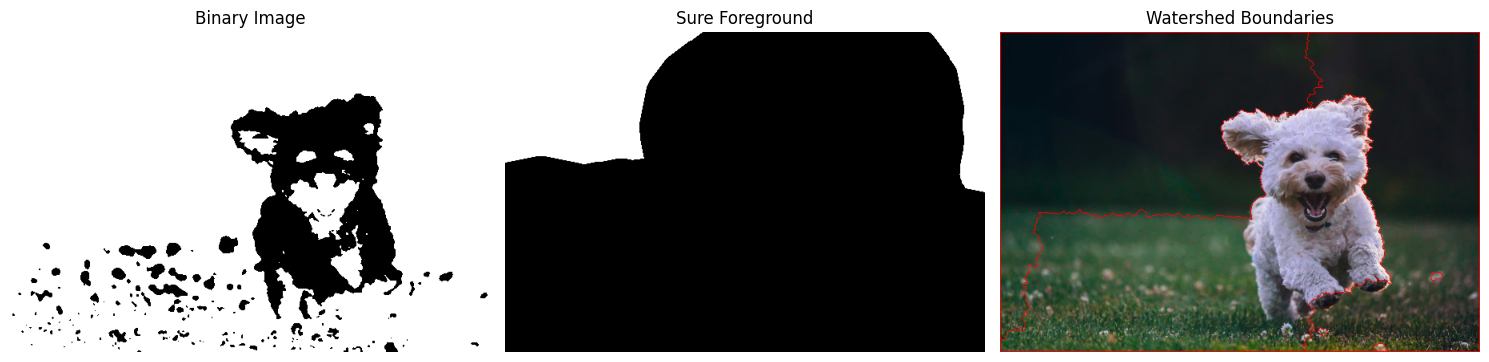

Watershed Segmentation Completed
Number of connected foreground markers: 2


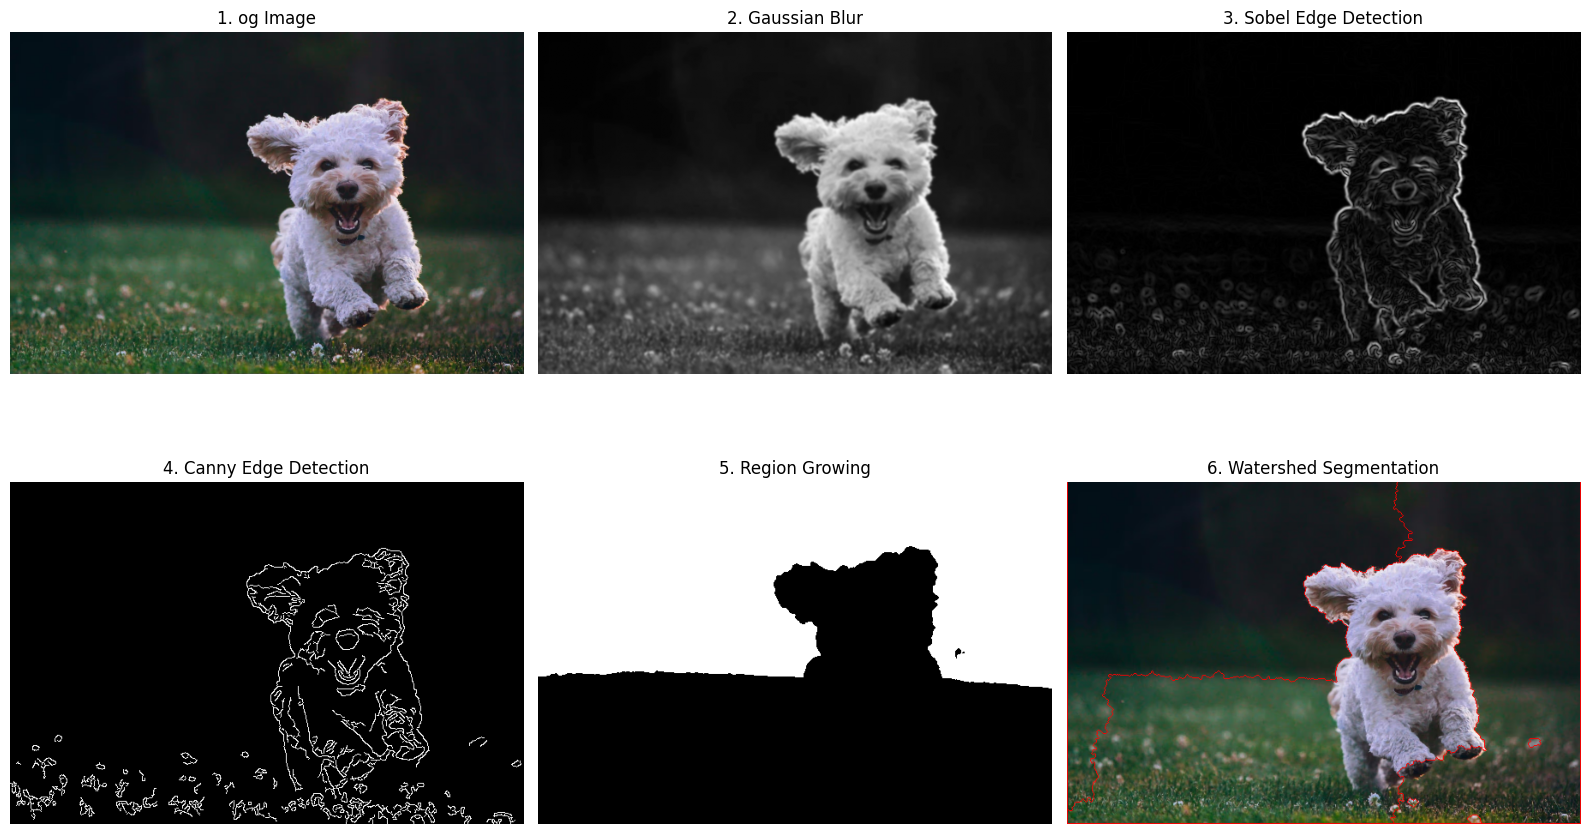

In [ ]:
uploaded = files.upload()
filename = list(uploaded.keys())[0]
image = cv2.imread(filename)
if image is None:
    raise ValueError("Unable to read the uploaded image.")
image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]
if max(height, width) > 600:
    scale=600/max(height,width)
    image=cv2.resize(image,(int(width*scale),int(height*scale)))

gray=cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)
print("Image dimensions:", image.shape)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("og img")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("grayscale img")
plt.axis("off")
plt.tight_layout()
plt.show()


blurred = cv2.GaussianBlur(gray, (5, 5), 0)
plt.figure(figsize=(12, 5))
# plt.subplot(1, 2, 1)
# plt.imshow(gray, cmap="gray")
# plt.title("Grayscale Image")
# plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blurred img")
plt.axis("off")

plt.tight_layout()
plt.show()


sobel_x=cv2.Sobel(blurred,cv2.CV_64F,1,0,ksize=3)
sobel_y=cv2.Sobel(blurred,cv2.CV_64F,0,1,ksize=3)

sobel_magnitude=np.sqrt(sobel_x**2+sobel_y**2)
sobel_edges=cv2.normalize(sobel_magnitude,None,0,255,cv2.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(12, 5))
plt.subplot(1,2,1)
plt.imshow(sobel_edges,cmap="gray")
plt.title("Sobel Edge Detection")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image)
plt.imshow(sobel_edges, cmap="jet", alpha=0.6)
plt.title("Sobel Edges on og Image")
plt.axis("off")
plt.tight_layout()
plt.show()


canny_edges=cv2.Canny(blurred,50,150)
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(image)
plt.title("og Image")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(canny_edges,cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.tight_layout()
plt.show()


def region_growing(gray, seed_x, seed_y, threshold=15):
    height, width = gray.shape

    segmented = np.zeros((height, width), dtype=np.uint8)
    queue = deque([(seed_y, seed_x)])
    segmented[seed_y, seed_x] = 255
    region_sum = int(gray[seed_y, seed_x])
    region_count = 1

    neighbors = [(-1, 0),(1, 0),(0, -1),(0, 1)]

    while queue:
        y, x = queue.popleft()
        mean_intensity=region_sum/region_count
        for dy, dx in neighbors:
            ny = y + dy
            nx = x + dx

            if 0 <= ny < height and 0 <= nx < width:
                if segmented[ny, nx] == 0:
                    pixel_value = int(gray[ny, nx])
                    if abs(pixel_value - mean_intensity) <= threshold:

                        segmented[ny, nx] = 255
                        queue.append((ny, nx))
                        region_sum += pixel_value
                        region_count += 1
    return segmented


seed_y = gray.shape[0]//2
seed_x = gray.shape[1]//2

grown_region = region_growing(blurred,seed_x,seed_y,threshold=15)
image_with_seed = image.copy()
cv2.circle(image_with_seed,(seed_x, seed_y),5,(255, 0, 0),-1)

plt.figure(figsize=(15, 5))

plt.subplot(1,3,1)
plt.imshow(image_with_seed)
plt.title("og Image with Seed")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(grown_region, cmap="gray")
plt.title("Region Growing Result")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(grown_region, cmap="spring", alpha=0.5)
plt.title("Region Growing Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

region_pixels = np.count_nonzero(grown_region)
print("Region Growing Completed")
print("Seed coordinates (x, y):", (seed_x, seed_y))
print("Number of segmented pixels:", region_pixels)

_,binary=cv2.threshold(blurred,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)

kernel=np.ones((3,3),np.uint8)
opening = cv2.morphologyEx(binary,cv2.MORPH_OPEN,kernel,iterations=2)
sure_background = cv2.dilate(opening,kernel,iterations=3)


distance = cv2.distanceTransform(opening,cv2.DIST_L2,5)

if distance.max() > 0:
    _,sure_foreground=cv2.threshold(distance,0.4*distance.max(),255,cv2.THRESH_BINARY)

else:
    sure_foreground = np.zeros_like(gray)

sure_foreground=sure_foreground.astype(np.uint8)

unknown = cv2.subtract(sure_background,sure_foreground)

num_labels, markers = cv2.connectedComponents(sure_foreground)

markers = markers + 1
markers[unknown == 255] = 0

image_bgr = cv2.cvtColor(image,cv2.COLOR_RGB2BGR)
markers = cv2.watershed(image_bgr,markers.astype(np.int32))

watershed_result = image.copy()
watershed_result[markers==-1]=[255,0,0]

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sure_foreground, cmap="gray")
plt.title("Sure Foreground")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(watershed_result)
plt.title("Watershed Boundaries")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Watershed Segmentation Completed")
print("Number of connected foreground markers:", num_labels - 1)


plt.figure(figsize=(16, 10))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("1. og Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(blurred, cmap="gray")
plt.title("2. Gaussian Blur")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(sobel_edges, cmap="gray")
plt.title("3. Sobel Edge Detection")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(canny_edges, cmap="gray")
plt.title("4. Canny Edge Detection")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(grown_region, cmap="gray")
plt.title("5. Region Growing")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(watershed_result)
plt.title("6. Watershed Segmentation")
plt.axis("off")
plt.tight_layout()
plt.show()